# Chapter 26 | Worked solutions

Image and Video Generation

These eleven solutions move from hand calculations to controlled sampler experiments and evaluation design. The small arrays are exact teaching fixtures, not generated images or measurements of a trained model. Exercises 9–11 give evaluation protocols; their numerical examples are explicitly hypothetical.

The central result is that removing the explicit noise term does not remove a mistaken clean estimate. Holding one prediction error fixed makes its effect traceable across two updates. Guidance then provides a second lesson: it extrapolates noise predictions and must be evaluated separately for adherence and variety.

## Setup

Run from this repository or a subdirectory after installing `requirements.txt`. The notebook uses the canonical NumPy helpers and Matplotlib. It downloads no models or data. Every assertion checks a derived value or a boundary condition.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch26_visual_generation/model.py").exists())
sys.path.insert(0, str(root))
from examples.ch26_visual_generation.model import (
    add_noise, ddim_step, guided_noise,
)
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "figure.figsize": (7, 3.6),
                     "axes.spines.top": False, "axes.spines.right": False})
print("Canonical helpers loaded; no model or data downloads.")

Canonical helpers loaded; no model or data downloads.


## 1. Mix signal and noise

At $a=0.64$, the signal amplitude is $\sqrt{a}=0.8$ and the noise amplitude is $\sqrt{1-a}=0.6$. Thus $x_t=0.8(2)+0.6(-1)=1.0$. At $a=0.36$, the weights become $0.6$ and $0.8$, so $x_t=1.2-0.8=0.4$. The smaller $a$ reduces the signal contribution and increases the noise contribution. The squared weights add to one; the amplitudes themselves add to $1.4$ in these examples.

The notation distinguishes a single forward-step coefficient from its product: two steps with $\beta_1=\beta_2=0.2$ give $\alpha_1=\alpha_2=0.8$ and $\bar\alpha_2=0.64$.

In [2]:
for a, expected in [(0.64, 1.0), (0.36, 0.4)]:
    value = add_noise(2.0, -1.0, a)
    np.testing.assert_allclose(value, expected)
    print(f"a={a:.2f}: weights={np.sqrt(a):.1f}, "
          f"{np.sqrt(1-a):.1f}; mixture={value:.1f}")
assert np.isclose(np.prod([0.8, 0.8]), 0.64)

a=0.64: weights=0.8, 0.6; mixture=1.0
a=0.36: weights=0.6, 0.8; mixture=0.4


## 2. Recover a clean estimate

The input is $x_t=1.0$. With predicted noise $-0.5$, the clean estimate is $(1-0.6(-0.5))/0.8=1.625$. At next level $b=0.81$, the sample is $0.9(1.625)+\sqrt{0.19}(-0.5)\approx1.244555$. With the exact noise $-1$, the clean estimate is $2$ and the next sample is $1.8-\sqrt{0.19}\approx1.364110$.

The noise error is $\delta\epsilon=0.5$. It affects both terms in the next sample. The clean-estimate change is $-(0.6/0.8)(0.5)=-0.375$, contributing $0.9(-0.375)=-0.3375$ to that sample. The direct noise contribution changes by $\sqrt{0.19}(0.5)\approx0.217945$. Together they produce $-0.119555$, exactly the difference between the two next samples. Subtracting estimated noise and retaining some estimated noise are separate contributions; here their errors partly cancel.

For a general fixed state at level $a>0$, changing the predicted noise by $\delta\epsilon$ changes the clean estimate by $-\sqrt{(1-a)/a}\,\delta\epsilon$. The following plot holds the prediction error at $0.5$ to isolate this algebraic sensitivity. It is not a model-error curve.

In [3]:
noisy = add_noise(2.0, -1.0, 0.64)
estimate, next_value = ddim_step(noisy, -0.5, 0.64, 0.81)
exact, next_exact = ddim_step(noisy, -1.0, 0.64, 0.81)
clean_contribution = 0.9 * (estimate - exact)
noise_contribution = np.sqrt(0.19) * 0.5
np.testing.assert_allclose(estimate, 1.625)
np.testing.assert_allclose(next_value - next_exact,
                           clean_contribution + noise_contribution)
print(f"Predicted: clean={estimate:.6f}, next={next_value:.6f}")
print(f"Exact:     clean={exact:.6f}, next={next_exact:.6f}")
print(f"Change: {clean_contribution:.6f} + {noise_contribution:.6f} "
      f"= {next_value-next_exact:.6f}")

Predicted: clean=1.625000, next=1.244555
Exact:     clean=2.000000, next=1.364110
Change: -0.337500 + 0.217945 = -0.119555


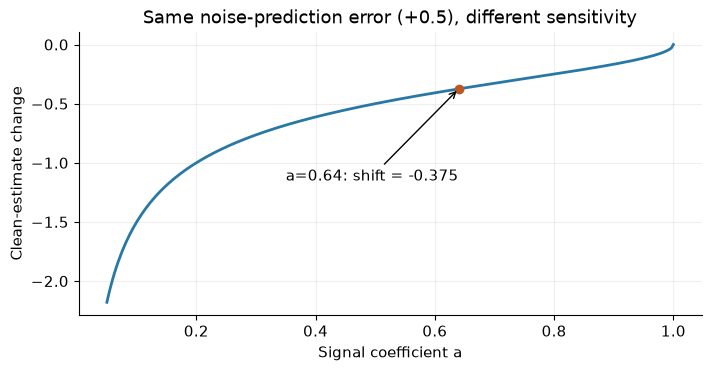

In [4]:
levels = np.linspace(0.05, 1, 300)
shifts = -np.sqrt((1-levels)/levels) * 0.5
fig, ax = plt.subplots(layout="constrained")
ax.plot(levels, shifts, color="#2878a5", linewidth=2)
ax.plot(0.64, -0.375, "o", color="#b85827")
ax.annotate("a=0.64: shift = -0.375", (0.64, -0.375),
            xytext=(0.35, -1.15), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="Signal coefficient a", ylabel="Clean-estimate change",
       title="Same noise-prediction error (+0.5), different sensitivity")
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

## 3. Change a guidance scale

The conditional-minus-unconditional direction is $(2,0)-(0,1)=(2,-1)$. Substitution in $u+g(c-u)$ gives $(0,1)$ at $g=0$, $(2,0)$ at $g=1$, and $(3,-0.5)$ at $g=1.5$. The third point lies beyond the conditional prediction on the line from unconditional to conditional. It is extrapolation, not an average confined between the endpoints. A negative noise coordinate is valid; these are not probabilities.

In [5]:
unconditional = np.array([0.0, 1.0])
conditional = np.array([2.0, 0.0])
for scale, expected in [(0, [0, 1]), (1, [2, 0]), (1.5, [3, -0.5])]:
    result = guided_noise(unconditional, conditional, scale)
    np.testing.assert_allclose(result, expected)
    print(f"g={scale}: {result}")

g=0: [0. 1.]
g=1: [2. 0.]
g=1.5: [ 3.  -0.5]


## 4. Count video attention pairs

For five frames and six patches per frame there are $30$ tokens. Joint attention uses $30^2=900$ ordered query–key pairs per clip and head. Spatial attention uses $5(6^2)=180$ pairs; temporal attention uses $6(5^2)=150$. One pass of each totals $330$, counting self-pairs separately in each pass.

The ratio $900/330\approx2.73$ compares pair counts only. Projections, feed-forward layers, attention kernels, memory traffic, batching, and the number of blocks and denoising calls also cost time. A spatial pass followed by a temporal pass can convey information from any frame and position to a query, but their composition is not the same operator as a single joint attention layer.

In [6]:
frames, patches = 5, 6
joint = (frames * patches) ** 2
spatial = frames * patches ** 2
temporal = patches * frames ** 2
assert (joint, spatial, temporal) == (900, 180, 150)
print(f"Joint={joint}; spatial={spatial}; temporal={temporal}")
print(f"Separate total={spatial+temporal}; pair ratio={joint/(spatial+temporal):.3f}")

Joint=900; spatial=180; temporal=150
Separate total=330; pair ratio=2.727


## 5. Check the endpoints

Choose clean array $[[1,2],[3,4]]$ and noise array $[[-1,0],[0.5,2]]$. At $a=0$, the signal term vanishes and `add_noise` returns the noise array. At $a=1$, the noise term vanishes and it returns the clean array. Both outputs retain shape $(2,2)$.

Calling `ddim_step` with current level zero raises `ValueError`. The clean-estimate formula divides by $\sqrt{a}$ and cannot infer a clean image from that endpoint by this algebra. The forward mixture is well-defined there because it never divides by the signal coefficient. A very small positive level and an exactly zero level are different cases.

In [7]:
clean_endpoint = np.array([[1., 2.], [3., 4.]])
noise_endpoint = np.array([[-1., 0.], [0.5, 2.]])
for a, expected in [(0, noise_endpoint), (1, clean_endpoint)]:
    result = add_noise(clean_endpoint, noise_endpoint, a)
    np.testing.assert_array_equal(result, expected)
    assert result.shape == (2, 2)
    print(f"a={a}, shape={result.shape}:\n{result}")
try:
    ddim_step(noise_endpoint, noise_endpoint, 0, 0.64)
except ValueError as error:
    print("Expected rejection:", error)
else:
    raise AssertionError("Zero current level must be rejected")

a=0, shape=(2, 2):
[[-1.   0. ]
 [ 0.5  2. ]]
a=1, shape=(2, 2):
[[1. 2.]
 [3. 4.]]
Expected rejection: use 0 < alpha_bar_t <= alpha_bar_next <= 1


## 6. Read both DDIM outputs

Use $x_0=I_2$ and $\epsilon=[[0,1],[-1,0]]$. At $a=0.36$, the input is $[[0.6,0.8],[-0.8,0.6]]$. The first call returns the clean estimate $I_2$ and the next sample $[[0.8,0.6],[-0.6,0.8]]$. These two outputs differ because the next sample deliberately retains noise at level $0.64$.

The second call takes that next sample, not the first clean estimate, as its input. With the same exact noise and next level one, both returned arrays equal $I_2$. The exact noise is supplied for this controlled calculation. A deployed model must predict it, and normally predicts again at each step.

In [8]:
clean = np.eye(2)
noise = np.array([[0., 1.], [-1., 0.]])
start = add_noise(clean, noise, 0.36)
estimate1, middle = ddim_step(start, noise, 0.36, 0.64)
estimate2, final = ddim_step(middle, noise, 0.64, 1.0)
np.testing.assert_allclose(estimate1, clean, atol=1e-14)
np.testing.assert_allclose(middle, [[0.8, 0.6], [-0.6, 0.8]])
np.testing.assert_allclose(estimate2, clean, atol=1e-14)
np.testing.assert_allclose(final, clean, atol=1e-14)
print("First clean estimate:\n", estimate1)
print("Next sample at 0.64:\n", middle)
print("Second clean estimate / final sample:\n", final)

First clean estimate:
 [[1. 0.]
 [0. 1.]]
Next sample at 0.64:
 [[ 0.8  0.6]
 [-0.6  0.8]]
Second clean estimate / final sample:
 [[1. 0.]
 [0. 1.]]


## 7. Change one prediction

Add $0.1$ once to the lower-left noise entry, changing it from $-1$ to $-0.9$, and reuse this altered prediction in both calls. Its first clean estimate is

$$
\frac{-0.8-0.8(-0.9)}{0.6}=-\frac{2}{15}.
$$

The next lower-left value is $0.8(-2/15)+0.6(-0.9)=-97/150\approx-0.646667$. The exact-prediction value is $-0.6$, so their difference is $-7/150\approx-0.046667$. In the second call, subtracting $0.6(-0.9)$ and dividing by $0.8$ recovers the same mistaken clean estimate $-2/15$. The final sample therefore has lower-left entry $-0.133333$ instead of zero. All other entries match the exact run because these elementwise operations never mix array entries.

This persistence follows algebraically: the next sample was formed as $\sqrt{b}\,\widehat{x}_0+\sqrt{1-b}\,\widehat\epsilon$. Subtracting the same noise term in the next call and dividing by $\sqrt{b}$ returns the same $\widehat{x}_0$. This experiment holds a prediction fixed to reveal that property; a trained denoiser would recompute its prediction.

In [9]:
perturbed = noise.copy()
perturbed[1, 0] += 0.1
bad_estimate1, bad_middle = ddim_step(start, perturbed, 0.36, 0.64)
bad_estimate2, bad_final = ddim_step(bad_middle, perturbed, 0.64, 1.0)
np.testing.assert_allclose(bad_middle[1, 0], -97/150)
np.testing.assert_allclose(bad_final[1, 0], -2/15)
np.testing.assert_allclose(bad_estimate1, bad_estimate2, atol=1e-14)
mask = np.array([[True, True], [False, True]])
np.testing.assert_allclose(bad_middle[mask], middle[mask])
np.testing.assert_allclose(bad_final[mask], final[mask], atol=1e-14)
print("Middle-state error:\n", bad_middle - middle)
print("Final-state error:\n", bad_final - final)

Middle-state error:
 [[ 0.        0.      ]
 [-0.046667  0.      ]]
Final-state error:
 [[ 0.        0.      ]
 [-0.133333  0.      ]]


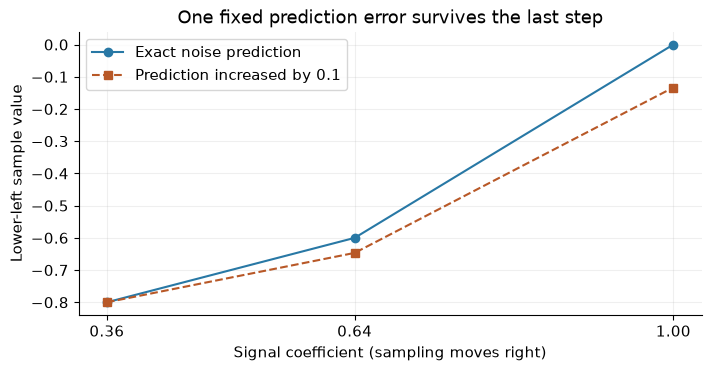

In [10]:
fig, ax = plt.subplots(layout="constrained")
levels = [0.36, 0.64, 1.0]
ax.plot(levels, [start[1, 0], middle[1, 0], final[1, 0]],
        "o-", label="Exact noise prediction", color="#2878a5")
ax.plot(levels, [start[1, 0], bad_middle[1, 0], bad_final[1, 0]],
        "s--", label="Prediction increased by 0.1", color="#b85827")
ax.set(xlabel="Signal coefficient (sampling moves right)",
       ylabel="Lower-left sample value", title="One fixed prediction error survives the last step")
ax.set_xticks(levels)
ax.legend(loc="upper left")
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

## 8. Sweep guidance

At scales $0,0.5,1,1.5,2$, the guided vectors are $(0,1)$, $(1,0.5)$, $(2,0)$, $(3,-0.5)$, and $(4,-1)$. Every increment of $0.5$ changes the vector by $(1,-0.5)$, which is half of $c-u=(2,-1)$. The points are equally spaced on a line. Guidance values above one continue beyond the conditional estimate; no normalization or clipping is part of this formula.

In [11]:
scales = np.linspace(0, 2, 5)
guided = np.stack([guided_noise(unconditional, conditional, g) for g in scales])
increments = np.diff(guided, axis=0)
np.testing.assert_allclose(increments, np.tile([1., -0.5], (4, 1)))
for scale, point in zip(scales, guided):
    print(f"g={scale:.1f}: {point}")
print("Every increment:", increments[0])

g=0.0: [0. 1.]
g=0.5: [1.  0.5]
g=1.0: [2. 0.]
g=1.5: [ 3.  -0.5]
g=2.0: [ 4. -1.]
Every increment: [ 1.  -0.5]


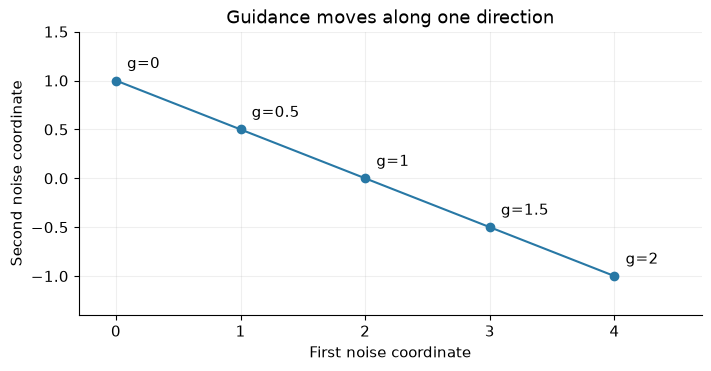

In [12]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(guided[:, 0], guided[:, 1], "o-", color="#2878a5")
for g, point in zip(scales, guided):
    ax.annotate(f"g={g:g}", point, xytext=(8, 9), textcoords="offset points")
ax.set(xlabel="First noise coordinate", ylabel="Second noise coordinate",
       title="Guidance moves along one direction", xlim=(-0.3, 4.7), ylim=(-1.4, 1.5))
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

## 9. Compare two sampling settings

Use one checkpoint and its supported scheduler parameterization. Choose 10-step and 30-step schedules from the same family and record the actual timestep or noise-level lists. Keep resolution, prompts, guidance scale, initial noise tensors, precision, hardware, and software fixed. Pair each prompt and initial tensor across both settings, then repeat across many prompts and seeds. If the chosen sampler is stochastic, also control and record its additional draws; deterministic DDIM avoids that extra source of variation. Saving an integer seed alone may not ensure identical tensors across implementations.

Warm up the model and synchronize accelerator work around timing. Report sampling latency from a ready model and, separately, end-to-end latency including the declared prompt-encoding and image-decoding stages. State whether model loading is included, and keep that boundary the same. Record peak memory if it matters to the comparison.

For a sampler making one prediction update per step, 10 and 30 steps require 10 and 30 denoiser evaluations without guidance. If every update uses both conditional and unconditional predictions, there are 20 and 60 prediction evaluations per sample. A concatenated batch can reduce these to 10 and 30 model invocations, each with twice the sample batch size. Other samplers may use several evaluations per step; count what actually runs. Neither count is a measured speedup.

Evaluate prompt adherence, visible defects, and variety separately using blinded, paired assessments and the complete output set. Report timing distributions and quality differences over the paired examples, not just a favorite image. These counts describe the stated sampler; they are not benchmark data.

In [13]:
for steps in [10, 30]:
    unconditional_evaluations = steps
    guided_evaluations = 2 * steps
    batched_guided_invocations = steps
    print(f"{steps} steps: {unconditional_evaluations} unguided evaluations; "
          f"{guided_evaluations} guided evaluations; "
          f"{batched_guided_invocations} batched guided invocations")

10 steps: 10 unguided evaluations; 20 guided evaluations; 10 batched guided invocations
30 steps: 30 unguided evaluations; 60 guided evaluations; 30 batched guided invocations


## 10. Check motion as well as appearance

Use prompts with explicit camera and object motion. For a marked cube rotating under a fixed camera, check the order and continuity of visible face markings across frames; a cube-shaped object in each still frame is insufficient. For a camera translating past a stationary statue, check consistent parallax and viewpoint change while the statue keeps its pose. For a fixed camera viewing a still life, track object positions and background landmarks for unwanted drift, flicker, or invented motion.

Record appearance, requested motion, identity continuity, and assessability in separate fields. An attractive cube that does not rotate can pass appearance and fail motion. Occlusion or inadequate visibility should yield an unassessable flag when it prevents a judgment, rather than an automatic pass. Repeat across prompts, seeds, durations, and frame rates, keeping settings fixed within each comparison. The accompanying notebook illustrates this scoring format with hypothetical records; no video model was run.

In [14]:
example_records = [
    {"case": "cube", "appearance": "pass", "motion": "fail", "assessable": True},
    {"case": "statue", "appearance": "pass", "motion": "pass", "assessable": True},
    {"case": "still life", "appearance": "unclear", "motion": "unassessable", "assessable": False},
]
assert example_records[0]["appearance"] != example_records[0]["motion"]
for record in example_records:
    print(record)

{'case': 'cube', 'appearance': 'pass', 'motion': 'fail', 'assessable': True}
{'case': 'statue', 'appearance': 'pass', 'motion': 'pass', 'assessable': True}
{'case': 'still life', 'appearance': 'unclear', 'motion': 'unassessable', 'assessable': False}


## 11. Separate variety from prompt following

Pair each prompt and initial noise tensor across the two guidance scales. Use a predefined checklist for required objects, attributes, counts, and relations. Report each criterion and the fraction satisfying all required criteria. Judge composition variety separately, with categories defined before comparing outcomes: for example, camera view, crop, and object placement. Different pixel noise or color shades need not constitute a different composition.

Eight samples form $\binom{8}{2}=28$ unordered pairs. With category counts $(4,2,1,1)$, the number of same-category pairs is $\binom{4}{2}+\binom{2}{2}=6+1=7$, giving $7/28=0.25$. For $(3,2,2,1)$ it is $3+1+1=5$, giving $5/28\approx0.1786$. Under these categories, the second set repeats compositions less often. This says nothing by itself about prompt adherence, image quality, or diversity within a category. Eight samples for one prompt do not establish a general ranking; repeat the comparison and report uncertainty and category definitions.

Saving only the strongest sample changes the question to performance after selection. It hides failure frequency and repetition, and introduces a selection budget and a selector. Preserve all draws; report ordinary-sample results and best-of-$N$ results separately with the same $N$ and selection rule for both scales.

In [15]:
from math import comb
composition_counts = [(4, 2, 1, 1), (3, 2, 2, 1)]
for counts, expected in zip(composition_counts, [7, 5]):
    total_pairs = comb(sum(counts), 2)
    repeated_pairs = sum(comb(count, 2) for count in counts)
    assert total_pairs == 28 and repeated_pairs == expected
    print(f"{counts}: {repeated_pairs}/{total_pairs} = {repeated_pairs/total_pairs:.4f}")

(4, 2, 1, 1): 7/28 = 0.2500
(3, 2, 2, 1): 5/28 = 0.1786


## Checks and next steps

All eleven exercises are covered above. The executed checks reproduce both sampler outputs, endpoint behavior, the one-entry error, guidance increments, attention counts, and composition-pair fractions. The three plots visualize these calculations. The evaluation examples are protocols and hypothetical records, not claims about any pretrained generator.

To extend the experiment, let the predicted noise change at each step and inspect whether the clean estimates move toward or away from the target. Keep that experiment distinct from the fixed-prediction calculation that explains the algebra here.